# Grid Search Analysis: SCM Model 06

This notebook analyzes the results of the grid search over:
- **BETA_RESPONDER**: Treatment effect for responders
- **phi**: AR(1) autocorrelation coefficient
- **ell**: Effect of temperature covariate on outcome

Metrics analyzed:
1. **BAI (Best Arm Identification)**: Accuracy of identifying the optimal treatment
2. **Optimal Treatment Fraction**: Fraction of time receiving the best treatment
3. **Bias**: Bias in estimating the treatment effect

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 1. Load Data

In [ ]:
# Configure the path to your grid search results
RESULTS_DIR = Path("../results/fu_grid_search_02")

# Find the most recent results files
summary_files = sorted(RESULTS_DIR.glob("grid_search_summary_*.csv"))
detailed_files = sorted(RESULTS_DIR.glob("grid_search_detailed_*.csv"))
params_files = sorted(RESULTS_DIR.glob("grid_search_params_*.json"))

if not summary_files:
    raise FileNotFoundError(f"No results found in {RESULTS_DIR}. Run the grid search first.")

# Load the most recent files
summary_path = summary_files[-1]
detailed_path = detailed_files[-1]
params_path = params_files[-1]

print(f"Loading results from:")
print(f"  Summary: {summary_path.name}")
print(f"  Detailed: {detailed_path.name}")
print(f"  Params: {params_path.name}")

Loading results from:
  Summary: grid_search_summary_20260204_224705.csv
  Detailed: grid_search_detailed_20260204_224705.csv
  Params: grid_search_params_20260204_224705.json


In [28]:
# Load the data
summary_df = pd.read_csv(summary_path)
detailed_df = pd.read_csv(detailed_path)

with open(params_path) as f:
    params = json.load(f)

print(f"\nGrid Search Parameters:")
print(f"  beta values: {params['beta_values']}")
print(f"  phi values: {params['phi_values']}")
print(f"  ell values: {params['ell_values']}")
print(f"  n_patients: {params['n_patients']}")
print(f"\nTotal parameter combinations: {len(params['beta_values']) * len(params['phi_values']) * len(params['ell_values'])}")
print(f"Total rows in summary: {len(summary_df)}")
print(f"Total rows in detailed: {len(detailed_df)}")


Grid Search Parameters:
  beta values: [0.1, 0.2, 0.3]
  phi values: [0.0, 0.3, 0.6, 0.9]
  ell values: [0.0, 0.1, 0.2]
  n_patients: 100

Total parameter combinations: 36
Total rows in summary: 180
Total rows in detailed: 36000


In [29]:
# Preview the summary data
summary_df.head(10)

,param_beta,param_phi,param_ell,policy,bai_accuracy,bai_accuracy_std,optimal_treatment_fraction_responder,optimal_treatment_fraction_responder_std,bias_responder,bias_responder_std,mae_responder,optimal_treatment_fraction_non_responder,bias_non_responder,mae_non_responder
0,0.1,0.0,0.0,Always Treat,0.00,0.000000,1.00000,0.000000,-0.100000,2.789540e-17,0.100000,1.00000,0.000000,0.000000
1,0.1,0.0,0.0,Fixed Randomization,0.74,0.440844,0.50000,0.000000,-0.017597,1.399392e-01,0.109548,0.50000,-0.027586,0.108205
2,0.1,0.0,0.0,Never Treat,0.00,0.000000,0.00000,0.000000,-0.100000,2.789540e-17,0.100000,0.00000,0.000000,0.000000
3,0.1,0.0,0.0,Thompson Sampling (no cov),0.73,0.446196,0.52750,0.203799,-0.014830,1.545128e-01,0.125327,0.48875,0.006628,0.100708
4,0.1,0.0,0.0,Thompson Sampling (with cov),0.74,0.440844,0.53875,0.212232,0.005193,1.563916e-01,0.128125,0.47250,0.004941,0.116498
5,0.1,0.0,0.1,Always Treat,0.00,0.000000,1.00000,0.000000,-0.100000,2.789540e-17,0.100000,1.00000,0.000000,0.000000
6,0.1,0.0,0.1,Fixed Randomization,0.72,0.451261,0.50000,0.000000,-0.015968,1.399510e-01,0.108270,0.50000,-0.015158,0.108362
7,0.1,0.0,0.1,Never Treat,0.00,0.000000,0.00000,0.000000,-0.100000,2.789540e-17,0.100000,0.00000,0.000000,0.000000
8,0.1,0.0,0.1,Thompson Sampling (no cov),0.81,0.394277,0.48500,0.196465,0.008779,1.399641e-01,0.109279,0.52375,-0.012728,0.106434
9,0.1,0.0,0.1,Thompson Sampling (with cov),0.72,0.451261,0.53375,0.193694,-0.006121,1.603361e-01,0.124705,0.55000,0.018359,0.118211


In [30]:
# Get unique values
policies = summary_df['policy'].unique()
beta_values = sorted(summary_df['param_beta'].unique())
phi_values = sorted(summary_df['param_phi'].unique())
ell_values = sorted(summary_df['param_ell'].unique())

print(f"Policies: {list(policies)}")
print(f"Beta values: {beta_values}")
print(f"Phi values: {phi_values}")
print(f"Ell values: {ell_values}")

Policies: ['Always Treat', 'Fixed Randomization', 'Never Treat', 'Thompson Sampling (no cov)', 'Thompson Sampling (with cov)']
Beta values: [np.float64(0.1), np.float64(0.2), np.float64(0.3)]
Phi values: [np.float64(0.0), np.float64(0.3), np.float64(0.6), np.float64(0.9)]
Ell values: [np.float64(0.0), np.float64(0.1), np.float64(0.2)]


## 2. Best Arm Identification (BAI) Analysis

BAI measures how accurately each policy identifies the optimal treatment for responders.

In [31]:
def plot_metric_by_parameter(df, metric_col, param_col, param_label, metric_label, 
                              title=None, ylim=None, ax=None):
    """Plot a metric against a parameter, grouped by policy."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))
    
    # Group and aggregate
    grouped = df.groupby([param_col, 'policy'])[metric_col].agg(['mean', 'std']).reset_index()
    
    for policy in df['policy'].unique():
        policy_data = grouped[grouped['policy'] == policy]
        ax.errorbar(
            policy_data[param_col], 
            policy_data['mean'],
            yerr=policy_data['std'],
            marker='o', 
            label=policy,
            capsize=3,
            capthick=1
        )
    
    ax.set_xlabel(param_label)
    ax.set_ylabel(metric_label)
    if title:
        ax.set_title(title)
    if ylim:
        ax.set_ylim(ylim)
    ax.legend(loc='best')
    
    return ax

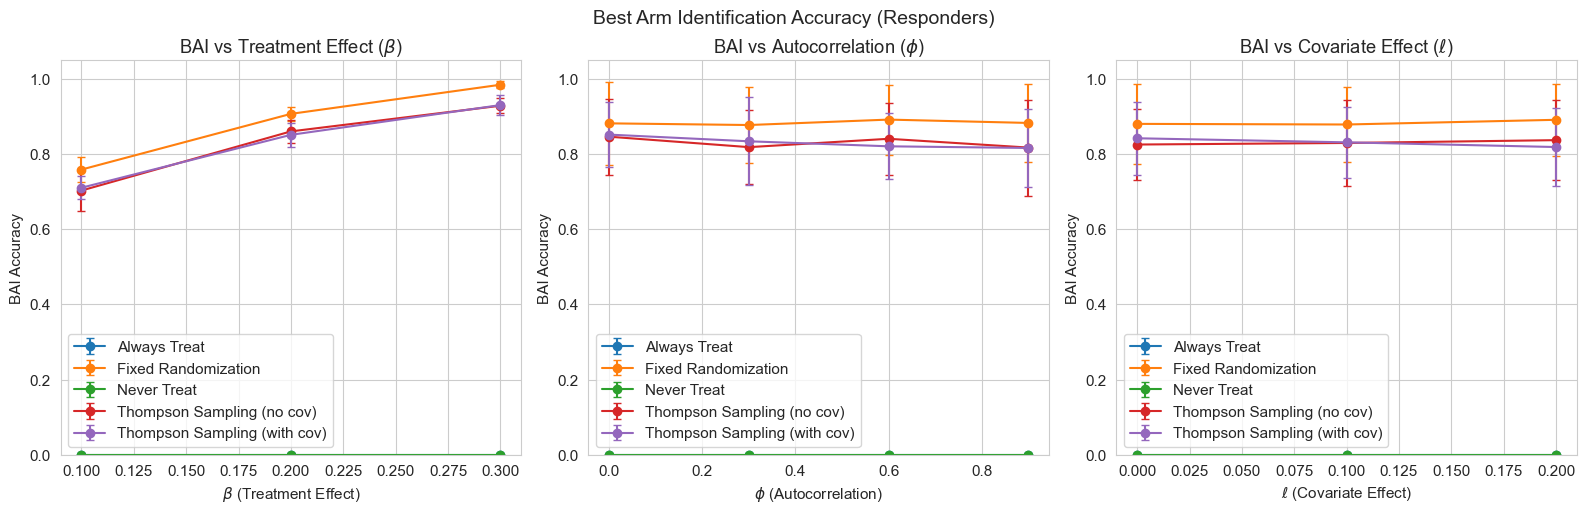

In [32]:
# BAI vs each parameter
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_metric_by_parameter(
    summary_df, 'bai_accuracy', 'param_beta', 
    r'$\beta$ (Treatment Effect)', 'BAI Accuracy',
    title=r'BAI vs Treatment Effect ($\beta$)', ylim=(0, 1.05), ax=axes[0]
)

plot_metric_by_parameter(
    summary_df, 'bai_accuracy', 'param_phi', 
    r'$\phi$ (Autocorrelation)', 'BAI Accuracy',
    title=r'BAI vs Autocorrelation ($\phi$)', ylim=(0, 1.05), ax=axes[1]
)

plot_metric_by_parameter(
    summary_df, 'bai_accuracy', 'param_ell', 
    r'$\ell$ (Covariate Effect)', 'BAI Accuracy',
    title=r'BAI vs Covariate Effect ($\ell$)', ylim=(0, 1.05), ax=axes[2]
)

plt.tight_layout()
plt.suptitle('Best Arm Identification Accuracy (Responders)', y=1.02, fontsize=14)
plt.savefig(RESULTS_DIR / 'bai_by_parameter.pdf', bbox_inches='tight')
plt.show()

<>:21: SyntaxWarning: invalid escape sequence '\e'
<>:21: SyntaxWarning: invalid escape sequence '\e'
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81361/3238571365.py:21: SyntaxWarning: invalid escape sequence '\e'
  plt.suptitle('BAI Accuracy Heatmaps (averaged over $\ell$)', y=1.02, fontsize=14)


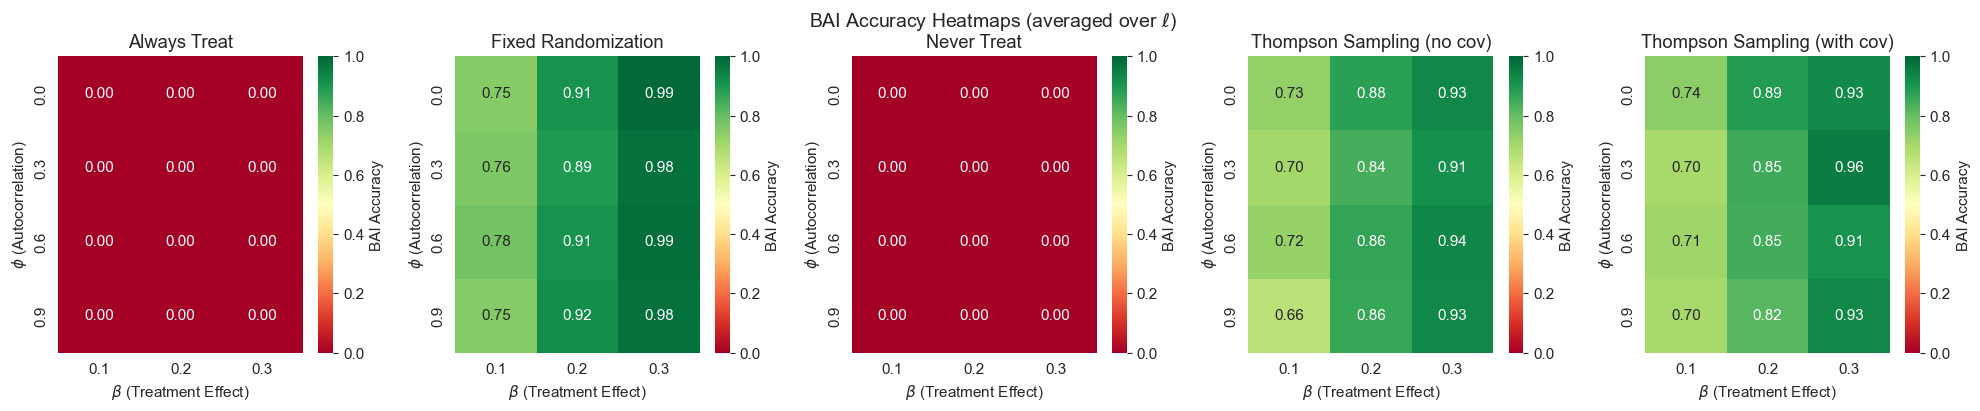

In [33]:
# Heatmap: BAI for each policy across beta and phi (averaged over ell)
fig, axes = plt.subplots(1, len(policies), figsize=(4*len(policies), 4))
if len(policies) == 1:
    axes = [axes]

for ax, policy in zip(axes, policies):
    policy_df = summary_df[summary_df['policy'] == policy]
    pivot = policy_df.pivot_table(
        values='bai_accuracy', 
        index='param_phi', 
        columns='param_beta',
        aggfunc='mean'
    )
    sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn', 
                vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'BAI Accuracy'})
    ax.set_title(f'{policy}')
    ax.set_xlabel(r'$\beta$ (Treatment Effect)')
    ax.set_ylabel(r'$\phi$ (Autocorrelation)')

plt.tight_layout()
plt.suptitle('BAI Accuracy Heatmaps (averaged over $\ell$)', y=1.02, fontsize=14)
plt.savefig(RESULTS_DIR / 'bai_heatmaps.pdf', bbox_inches='tight')
plt.show()

## 3. Time of Optimal Treatment Analysis

This metric measures the fraction of periods where the patient received the optimal treatment.

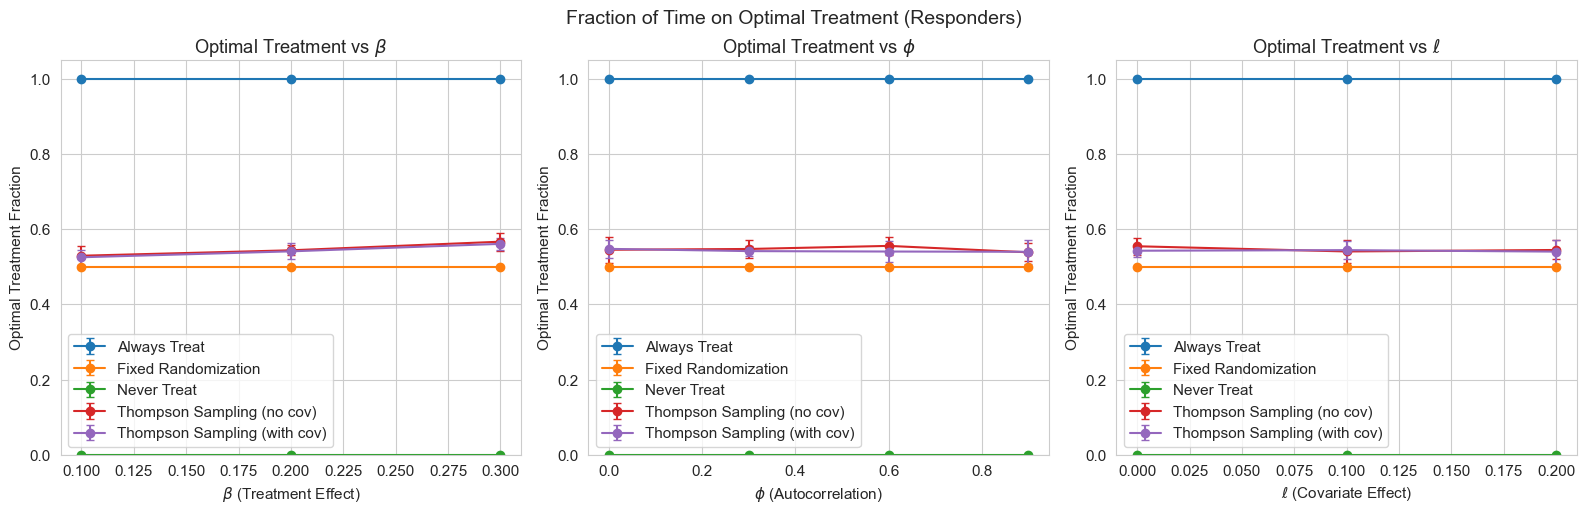

In [50]:
# Optimal treatment fraction vs each parameter (responders)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_metric_by_parameter(
    summary_df, 'optimal_treatment_fraction_responder', 'param_beta', 
    r'$\beta$ (Treatment Effect)', 'Optimal Treatment Fraction',
    title=r'Optimal Treatment vs $\beta$', ylim=(0, 1.05), ax=axes[0]
)

plot_metric_by_parameter(
    summary_df, 'optimal_treatment_fraction_responder', 'param_phi', 
    r'$\phi$ (Autocorrelation)', 'Optimal Treatment Fraction',
    title=r'Optimal Treatment vs $\phi$', ylim=(0, 1.05), ax=axes[1]
)

plot_metric_by_parameter(
    summary_df, 'optimal_treatment_fraction_responder', 'param_ell', 
    r'$\ell$ (Covariate Effect)', 'Optimal Treatment Fraction',
    title=r'Optimal Treatment vs $\ell$', ylim=(0, 1.05), ax=axes[2]
)

plt.tight_layout()
plt.suptitle('Fraction of Time on Optimal Treatment (Responders)', y=1.02, fontsize=14)
plt.savefig(RESULTS_DIR / 'optimal_treatment_by_parameter.pdf', bbox_inches='tight')
plt.show()

/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81361/3117311186.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81361/3117311186.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


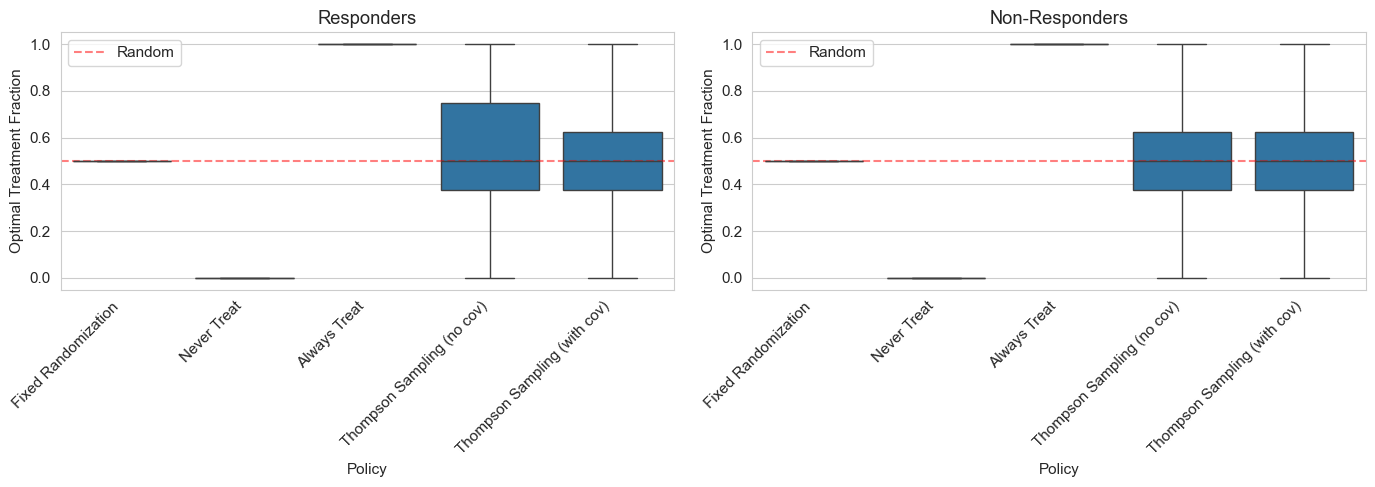

In [51]:
# Box plot comparison across policies
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Responders
responder_detailed = detailed_df[detailed_df['is_responder'] == True]
sns.boxplot(data=responder_detailed, x='policy', y='optimal_treatment_fraction', ax=axes[0])
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_ylabel('Optimal Treatment Fraction')
axes[0].set_xlabel('Policy')
axes[0].set_title('Responders')
axes[0].axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Random')
axes[0].legend()

# Non-responders
non_responder_detailed = detailed_df[detailed_df['is_responder'] == False]
sns.boxplot(data=non_responder_detailed, x='policy', y='optimal_treatment_fraction', ax=axes[1])
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_ylabel('Optimal Treatment Fraction')
axes[1].set_xlabel('Policy')
axes[1].set_title('Non-Responders')
axes[1].axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Random')
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'optimal_treatment_boxplots.pdf', bbox_inches='tight')
plt.show()

## 4. Bias Analysis

This metric measures the bias in estimating the treatment effect through adaptive data collection.

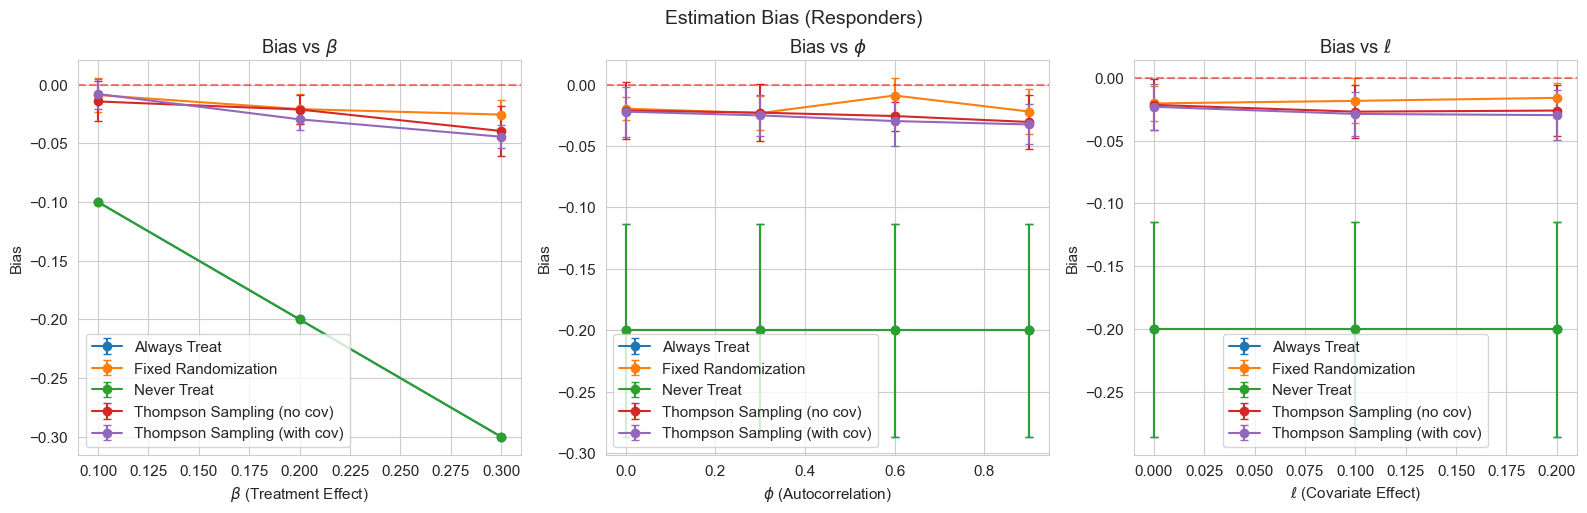

In [52]:
# Bias vs each parameter (responders)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_metric_by_parameter(
    summary_df, 'bias_responder', 'param_beta', 
    r'$\beta$ (Treatment Effect)', 'Bias',
    title=r'Bias vs $\beta$', ax=axes[0]
)
axes[0].axhline(y=0, color='r', linestyle='--', alpha=0.5)

plot_metric_by_parameter(
    summary_df, 'bias_responder', 'param_phi', 
    r'$\phi$ (Autocorrelation)', 'Bias',
    title=r'Bias vs $\phi$', ax=axes[1]
)
axes[1].axhline(y=0, color='r', linestyle='--', alpha=0.5)

plot_metric_by_parameter(
    summary_df, 'bias_responder', 'param_ell', 
    r'$\ell$ (Covariate Effect)', 'Bias',
    title=r'Bias vs $\ell$', ax=axes[2]
)
axes[2].axhline(y=0, color='r', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.suptitle('Estimation Bias (Responders)', y=1.02, fontsize=14)
plt.savefig(RESULTS_DIR / 'bias_by_parameter.pdf', bbox_inches='tight')
plt.show()

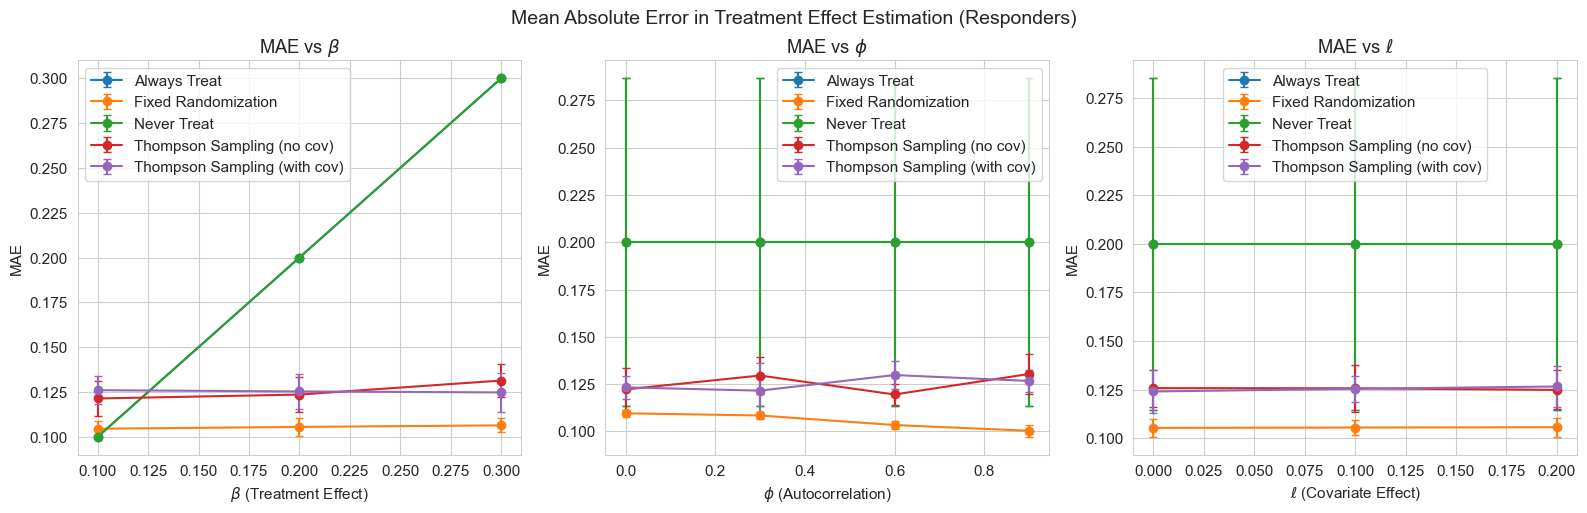

In [53]:
# Mean Absolute Error vs each parameter
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_metric_by_parameter(
    summary_df, 'mae_responder', 'param_beta', 
    r'$\beta$ (Treatment Effect)', 'MAE',
    title=r'MAE vs $\beta$', ax=axes[0]
)

plot_metric_by_parameter(
    summary_df, 'mae_responder', 'param_phi', 
    r'$\phi$ (Autocorrelation)', 'MAE',
    title=r'MAE vs $\phi$', ax=axes[1]
)

plot_metric_by_parameter(
    summary_df, 'mae_responder', 'param_ell', 
    r'$\ell$ (Covariate Effect)', 'MAE',
    title=r'MAE vs $\ell$', ax=axes[2]
)

plt.tight_layout()
plt.suptitle('Mean Absolute Error in Treatment Effect Estimation (Responders)', y=1.02, fontsize=14)
plt.savefig(RESULTS_DIR / 'mae_by_parameter.pdf', bbox_inches='tight')
plt.show()

/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81361/1607600334.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81361/1607600334.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


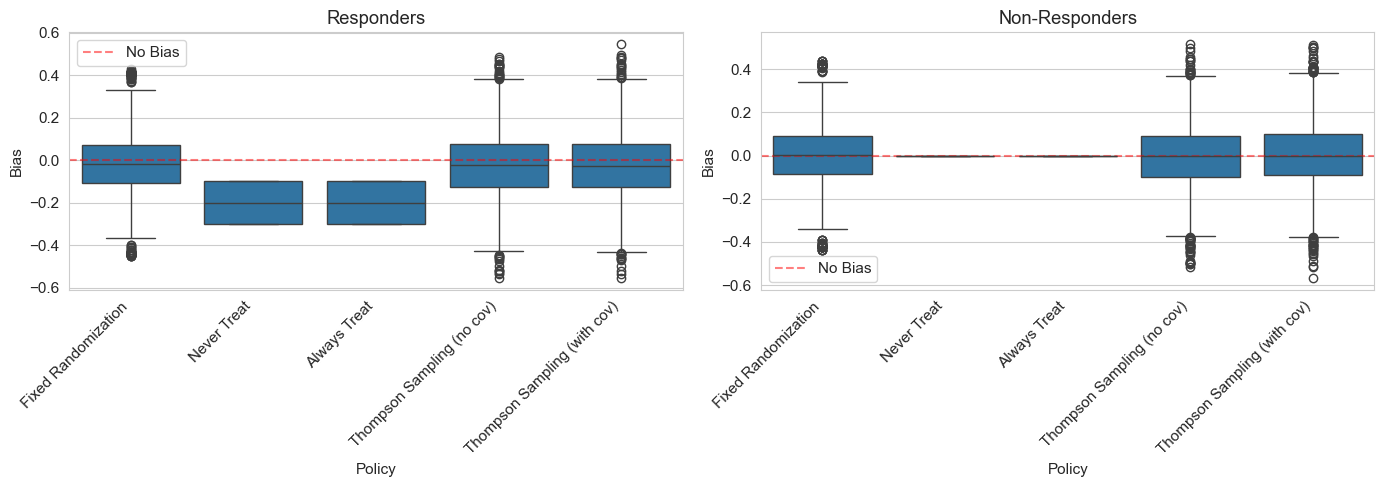

In [54]:
# Bias distribution by policy (detailed data)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Responders
sns.boxplot(data=responder_detailed, x='policy', y='bias', ax=axes[0])
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_ylabel('Bias')
axes[0].set_xlabel('Policy')
axes[0].set_title('Responders')
axes[0].axhline(y=0, color='r', linestyle='--', alpha=0.5, label='No Bias')
axes[0].legend()

# Non-responders
sns.boxplot(data=non_responder_detailed, x='policy', y='bias', ax=axes[1])
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_ylabel('Bias')
axes[1].set_xlabel('Policy')
axes[1].set_title('Non-Responders')
axes[1].axhline(y=0, color='r', linestyle='--', alpha=0.5, label='No Bias')
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'bias_boxplots.pdf', bbox_inches='tight')
plt.show()

## 5. Combined Summary Visualization

In [55]:
# Summary table: mean metrics by policy (averaged over all parameters)
policy_summary = summary_df.groupby('policy').agg({
    'bai_accuracy': ['mean', 'std'],
    'optimal_treatment_fraction_responder': ['mean', 'std'],
    'bias_responder': ['mean', 'std'],
    'mae_responder': ['mean', 'std'],
}).round(3)

policy_summary.columns = ['_'.join(col).strip() for col in policy_summary.columns.values]
policy_summary

,bai_accuracy_mean,bai_accuracy_std,optimal_treatment_fraction_responder_mean,optimal_treatment_fraction_responder_std,bias_responder_mean,bias_responder_std,mae_responder_mean,mae_responder_std
policy,,,,,,,,
Always Treat,0.000,0.000,1.000,0.000,-0.200,0.083,0.200,0.083
Fixed Randomization,0.884,0.098,0.500,0.000,-0.018,0.015,0.105,0.004
Never Treat,0.000,0.000,0.000,0.000,-0.200,0.083,0.200,0.083
Thompson Sampling (no cov),0.831,0.103,0.547,0.027,-0.025,0.020,0.125,0.010
Thompson Sampling (with cov),0.831,0.097,0.543,0.024,-0.027,0.018,0.125,0.009


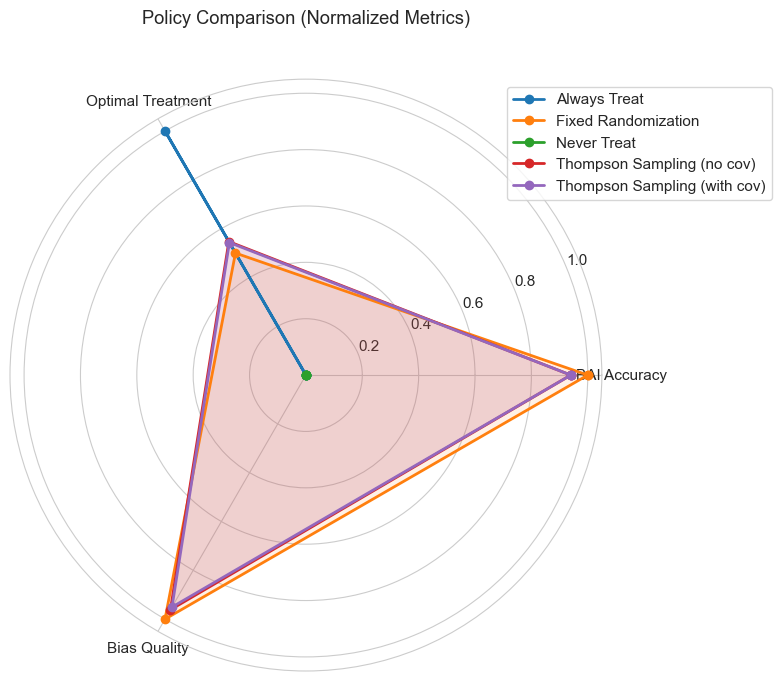

In [56]:
# Radar chart comparing policies
from math import pi

# Prepare data for radar chart
metrics = ['bai_accuracy_mean', 'optimal_treatment_fraction_responder_mean']
# For bias, we want lower absolute value to be better, so we use 1 - |bias|
policy_summary['bias_quality'] = 1 - policy_summary['bias_responder_mean'].abs()
metrics.append('bias_quality')

# Normalize metrics to [0, 1] for radar chart
radar_data = policy_summary[metrics].copy()
for col in radar_data.columns:
    radar_data[col] = (radar_data[col] - radar_data[col].min()) / (radar_data[col].max() - radar_data[col].min() + 1e-10)

# Number of metrics
N = len(metrics)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for policy in radar_data.index:
    values = radar_data.loc[policy].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=policy)
    ax.fill(angles, values, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(['BAI Accuracy', 'Optimal Treatment', 'Bias Quality'])
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
plt.title('Policy Comparison (Normalized Metrics)', y=1.08)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'policy_radar_chart.pdf', bbox_inches='tight')
plt.show()

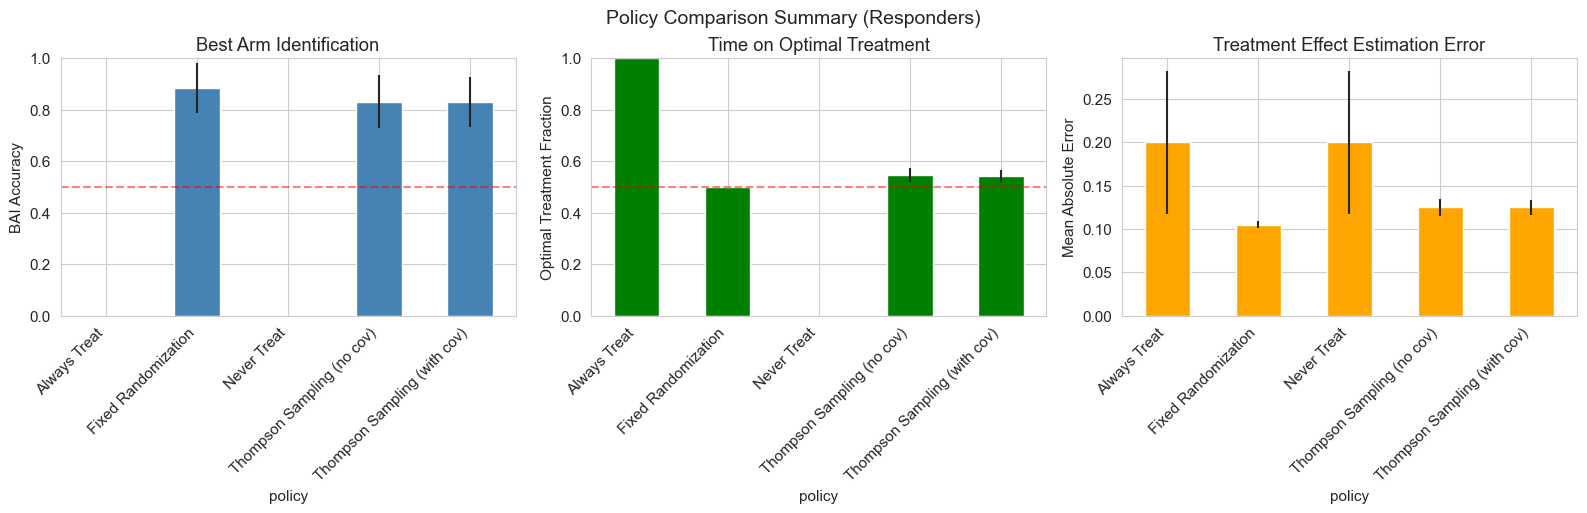

In [57]:
# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# BAI
policy_summary['bai_accuracy_mean'].plot(kind='bar', ax=axes[0], color='steelblue', yerr=policy_summary['bai_accuracy_std'])
axes[0].set_ylabel('BAI Accuracy')
axes[0].set_title('Best Arm Identification')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].axhline(y=0.5, color='r', linestyle='--', alpha=0.5)
axes[0].set_ylim(0, 1)

# Optimal treatment
policy_summary['optimal_treatment_fraction_responder_mean'].plot(
    kind='bar', ax=axes[1], color='green', 
    yerr=policy_summary['optimal_treatment_fraction_responder_std']
)
axes[1].set_ylabel('Optimal Treatment Fraction')
axes[1].set_title('Time on Optimal Treatment')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].axhline(y=0.5, color='r', linestyle='--', alpha=0.5)
axes[1].set_ylim(0, 1)

# MAE
policy_summary['mae_responder_mean'].plot(
    kind='bar', ax=axes[2], color='orange',
    yerr=policy_summary['mae_responder_std']
)
axes[2].set_ylabel('Mean Absolute Error')
axes[2].set_title('Treatment Effect Estimation Error')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.suptitle('Policy Comparison Summary (Responders)', y=1.02, fontsize=14)
plt.savefig(RESULTS_DIR / 'policy_comparison_bars.pdf', bbox_inches='tight')
plt.show()

## 6. Parameter Interaction Effects

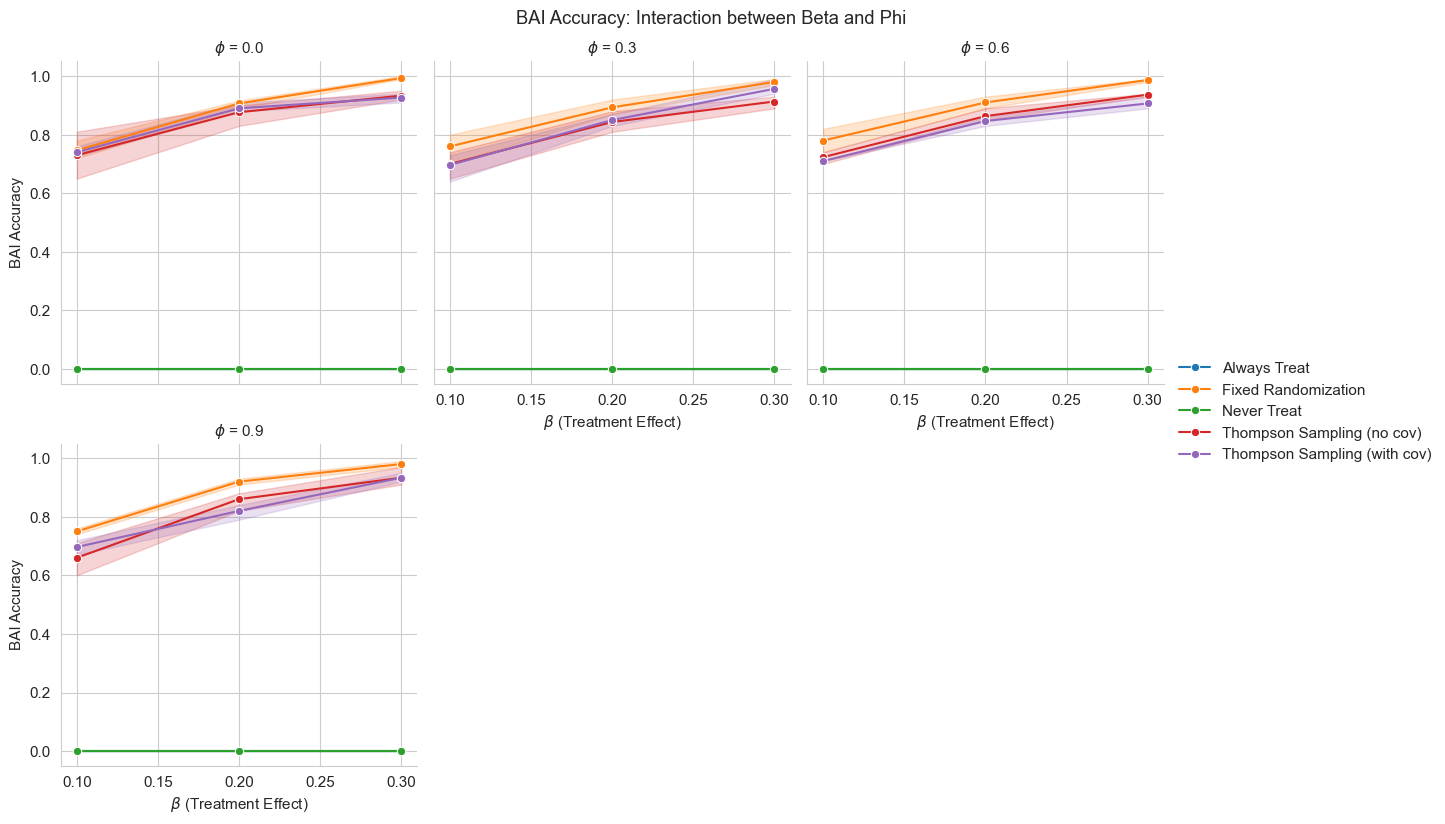

In [58]:
# Faceted plots: BAI by beta, faceted by phi
g = sns.FacetGrid(
    summary_df, 
    col='param_phi', 
    col_wrap=3, 
    height=4,
    sharey=True
)
g.map_dataframe(
    sns.lineplot, 
    x='param_beta', 
    y='bai_accuracy', 
    hue='policy',
    marker='o'
)
g.add_legend()
g.set_axis_labels(r'$\beta$ (Treatment Effect)', 'BAI Accuracy')
g.set_titles(r'$\phi$ = {col_name}')
g.fig.suptitle('BAI Accuracy: Interaction between Beta and Phi', y=1.02)
plt.savefig(RESULTS_DIR / 'bai_beta_phi_interaction.pdf', bbox_inches='tight')
plt.show()

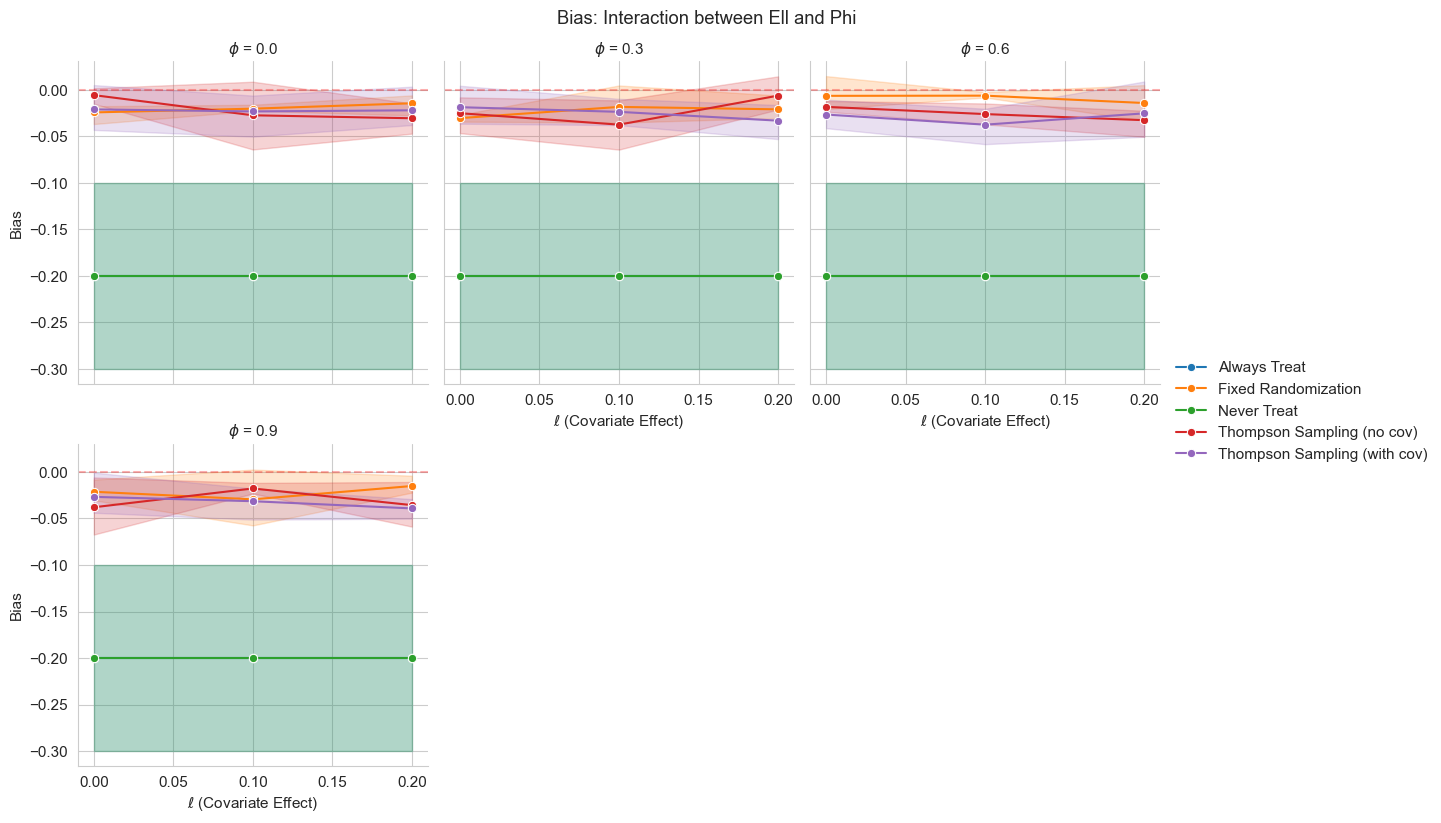

In [59]:
# Faceted plots: Bias by ell, faceted by phi
g = sns.FacetGrid(
    summary_df, 
    col='param_phi', 
    col_wrap=3, 
    height=4,
    sharey=True
)
g.map_dataframe(
    sns.lineplot, 
    x='param_ell', 
    y='bias_responder', 
    hue='policy',
    marker='o'
)
g.add_legend()
g.set_axis_labels(r'$\ell$ (Covariate Effect)', 'Bias')
g.set_titles(r'$\phi$ = {col_name}')
for ax in g.axes.flat:
    ax.axhline(y=0, color='r', linestyle='--', alpha=0.3)
g.fig.suptitle('Bias: Interaction between Ell and Phi', y=1.02)
plt.savefig(RESULTS_DIR / 'bias_ell_phi_interaction.pdf', bbox_inches='tight')
plt.show()

## 7. Statistical Summary Tables

In [60]:
# Detailed summary by parameter and policy
def create_summary_table(df, metric, group_by_param):
    """Create a summary table for a metric grouped by parameter."""
    table = df.pivot_table(
        values=metric,
        index=group_by_param,
        columns='policy',
        aggfunc=['mean', 'std']
    ).round(3)
    return table

print("BAI Accuracy by Beta:")
display(create_summary_table(summary_df, 'bai_accuracy', 'param_beta'))

BAI Accuracy by Beta:


mean                                  \
policy     Always Treat Fixed Randomization Never Treat   
param_beta                                                
0.1                 0.0               0.759         0.0   
0.2                 0.0               0.908         0.0   
0.3                 0.0               0.985         0.0   

                                                                    \
policy     Thompson Sampling (no cov) Thompson Sampling (with cov)   
param_beta                                                           
0.1                             0.703                        0.711   
0.2                             0.861                        0.852   
0.3                             0.929                        0.931   

                    std                                  \
policy     Always Treat Fixed Randomization Never Treat   
param_beta                                                
0.1                 0.0               0.034         0.0   
0.2                 0.0               0.019         0.0   
0.3                 0.0               0.009         0.0   

                                                                    
policy     Thompson Sampling (no cov) Thompson Sampling (with cov)  
param_beta                                                          
0.1                             0.055                        0.031  
0.2                             0.031                        0.031  
0.3                             0.020                        0.026

In [61]:
print("BAI Accuracy by Phi:")
display(create_summary_table(summary_df, 'bai_accuracy', 'param_phi'))

BAI Accuracy by Phi:


mean                                  \
policy    Always Treat Fixed Randomization Never Treat   
param_phi                                                
0.0                0.0               0.882         0.0   
0.3                0.0               0.878         0.0   
0.6                0.0               0.892         0.0   
0.9                0.0               0.883         0.0   

                                                                   \
policy    Thompson Sampling (no cov) Thompson Sampling (with cov)   
param_phi                                                           
0.0                            0.847                        0.852   
0.3                            0.819                        0.834   
0.6                            0.841                        0.821   
0.9                            0.818                        0.817   

                   std                                  \
policy    Always Treat Fixed Randomization Never Treat   
param_phi                                                
0.0                0.0               0.110         0.0   
0.3                0.0               0.100         0.0   
0.6                0.0               0.093         0.0   
0.9                0.0               0.104         0.0   

                                                                   
policy    Thompson Sampling (no cov) Thompson Sampling (with cov)  
param_phi                                                          
0.0                            0.102                        0.087  
0.3                            0.099                        0.117  
0.6                            0.095                        0.088  
0.9                            0.128                        0.104

In [62]:
print("BAI Accuracy by Ell:")
display(create_summary_table(summary_df, 'bai_accuracy', 'param_ell'))

BAI Accuracy by Ell:


mean                                  \
policy    Always Treat Fixed Randomization Never Treat   
param_ell                                                
0.0                0.0               0.881         0.0   
0.1                0.0               0.879         0.0   
0.2                0.0               0.892         0.0   

                                                                   \
policy    Thompson Sampling (no cov) Thompson Sampling (with cov)   
param_ell                                                           
0.0                            0.826                        0.842   
0.1                            0.830                        0.832   
0.2                            0.838                        0.819   

                   std                                  \
policy    Always Treat Fixed Randomization Never Treat   
param_ell                                                
0.0                0.0               0.106         0.0   
0.1                0.0               0.099         0.0   
0.2                0.0               0.096         0.0   

                                                                   
policy    Thompson Sampling (no cov) Thompson Sampling (with cov)  
param_ell                                                          
0.0                            0.095                        0.097  
0.1                            0.115                        0.095  
0.2                            0.106                        0.105

In [63]:
print("Bias by Beta:")
display(create_summary_table(summary_df, 'bias_responder', 'param_beta'))

Bias by Beta:


mean                                  \
policy     Always Treat Fixed Randomization Never Treat   
param_beta                                                
0.1                -0.1              -0.009        -0.1   
0.2                -0.2              -0.021        -0.2   
0.3                -0.3              -0.026        -0.3   

                                                                    \
policy     Thompson Sampling (no cov) Thompson Sampling (with cov)   
param_beta                                                           
0.1                            -0.014                       -0.008   
0.2                            -0.021                       -0.030   
0.3                            -0.039                       -0.044   

                    std                                  \
policy     Always Treat Fixed Randomization Never Treat   
param_beta                                                
0.1                 0.0               0.014         0.0   
0.2                 0.0               0.012         0.0   
0.3                 0.0               0.012         0.0   

                                                                    
policy     Thompson Sampling (no cov) Thompson Sampling (with cov)  
param_beta                                                          
0.1                             0.017                        0.013  
0.2                             0.013                        0.009  
0.3                             0.022                        0.010

In [48]:
# Export summary to LaTeX
latex_summary = policy_summary[[
    'bai_accuracy_mean', 'bai_accuracy_std',
    'optimal_treatment_fraction_responder_mean', 'optimal_treatment_fraction_responder_std',
    'bias_responder_mean', 'bias_responder_std'
]].copy()

latex_summary.columns = [
    'BAI Mean', 'BAI Std',
    'Opt. Treat. Mean', 'Opt. Treat. Std',
    'Bias Mean', 'Bias Std'
]

print("LaTeX Table:")
print(latex_summary.to_latex(float_format="%.3f"))

LaTeX Table:
\begin{tabular}{lrrrrrr}
\toprule
 & BAI Mean & BAI Std & Opt. Treat. Mean & Opt. Treat. Std & Bias Mean & Bias Std \\
policy &  &  &  &  &  &  \\
\midrule
Always Treat & 0.000 & 0.000 & 1.000 & 0.000 & -0.200 & 0.083 \\
Fixed Randomization & 0.884 & 0.098 & 0.500 & 0.000 & -0.018 & 0.015 \\
Never Treat & 0.000 & 0.000 & 0.000 & 0.000 & -0.200 & 0.083 \\
Thompson Sampling (no cov) & 0.831 & 0.103 & 0.547 & 0.027 & -0.025 & 0.020 \\
Thompson Sampling (with cov) & 0.831 & 0.097 & 0.543 & 0.024 & -0.027 & 0.018 \\
\bottomrule
\end{tabular}



## 8. Key Findings Summary

In [49]:
print("="*80)
print("KEY FINDINGS")
print("="*80)

# Best policy for BAI
best_bai_policy = policy_summary['bai_accuracy_mean'].idxmax()
best_bai_value = policy_summary['bai_accuracy_mean'].max()
print(f"\n1. Best policy for BAI: {best_bai_policy} ({best_bai_value:.1%})")

# Best policy for optimal treatment
best_treat_policy = policy_summary['optimal_treatment_fraction_responder_mean'].idxmax()
best_treat_value = policy_summary['optimal_treatment_fraction_responder_mean'].max()
print(f"\n2. Best policy for optimal treatment: {best_treat_policy} ({best_treat_value:.1%})")

# Best policy for bias (lowest absolute bias)
best_bias_policy = policy_summary['bias_responder_mean'].abs().idxmin()
best_bias_value = policy_summary.loc[best_bias_policy, 'bias_responder_mean']
print(f"\n3. Lowest bias policy: {best_bias_policy} (bias = {best_bias_value:.4f})")

# Effect of beta on BAI
bai_by_beta = summary_df.groupby('param_beta')['bai_accuracy'].mean()
print(f"\n4. Effect of beta on BAI:")
for beta, bai in bai_by_beta.items():
    print(f"   beta = {beta}: BAI = {bai:.1%}")

# Effect of phi on BAI
bai_by_phi = summary_df.groupby('param_phi')['bai_accuracy'].mean()
print(f"\n5. Effect of phi (autocorrelation) on BAI:")
for phi, bai in bai_by_phi.items():
    print(f"   phi = {phi}: BAI = {bai:.1%}")

# Effect of ell on bias
bias_by_ell = summary_df.groupby('param_ell')['bias_responder'].mean()
print(f"\n6. Effect of ell (covariate effect) on bias:")
for ell, bias in bias_by_ell.items():
    print(f"   ell = {ell}: bias = {bias:.4f}")

KEY FINDINGS

1. Best policy for BAI: Fixed Randomization (88.4%)

2. Best policy for optimal treatment: Always Treat (100.0%)

3. Lowest bias policy: Fixed Randomization (bias = -0.0180)

4. Effect of beta on BAI:
   beta = 0.1: BAI = 43.5%
   beta = 0.2: BAI = 52.4%
   beta = 0.3: BAI = 56.9%

5. Effect of phi (autocorrelation) on BAI:
   phi = 0.0: BAI = 51.6%
   phi = 0.3: BAI = 50.6%
   phi = 0.6: BAI = 51.1%
   phi = 0.9: BAI = 50.4%

6. Effect of ell (covariate effect) on bias:
   ell = 0.0: bias = -0.0931
   ell = 0.1: bias = -0.0949
   ell = 0.2: bias = -0.0944
